# Chapter 18: Capstone: A Full EDA

Companion notebook for *Master Exploratory Data Analysis: A Hands-On Beginner's Guide with Python, Statistics & A/B Testing*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files are in the same folder as this notebook.

## 18.2 The Plan of Attack

### Step one: understand what you have

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import confint_proportions_2indep
from statsmodels.stats.multitest import multipletests

plt.style.use('book.mplstyle')

customers = pd.read_csv('customers.csv', parse_dates=['signup_date'])
orders = pd.read_csv('orders.csv', parse_dates=['order_date'])
cancellations = pd.read_csv('cancellations.csv',
                            parse_dates=['cancel_date'])
tickets = pd.read_csv('support_tickets.csv',
                      parse_dates=['opened_date'])
survey = pd.read_csv('survey.csv', parse_dates=['response_date'])


def p_text(p):
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'


tickets.head()

,ticket_id,customer_id,opened_date,topic,hours_to_resolve
0,5001,1016,2024-01-11,Billing,19.4
1,5002,1023,2024-01-12,Other,0.7
2,5003,1033,2024-01-15,Change address,4.4
3,5004,1044,2024-01-18,Billing,3.6
4,5005,1047,2024-01-22,Late delivery,1.8


In [2]:
for name, table, date in [('tickets', tickets, 'opened_date'),
                          ('survey', survey, 'response_date')]:
    known = table['customer_id'].isin(customers['customer_id'])
    print(f'{name}: {len(table):,} rows, '
          f'{table.isna().sum().sum()} blanks, '
          f'{known.mean():.0%} known customers, '
          f'{table[date].min().date()} to '
          f'{table[date].max().date()}')

tickets: 1,380 rows, 0 blanks, 100% known customers, 2024-01-11 to 2025-12-31
survey: 532 rows, 0 blanks, 100% known customers, 2025-11-03 to 2025-11-12


### Step two: one variable at a time

In [3]:
print(tickets['topic'].value_counts())
print(tickets['hours_to_resolve'].describe().round(1))

topic
Late delivery      612
Billing            250
Product quality    214
Change address     153
Other              151
Name: count, dtype: int64
count    1380.0
mean        9.4
std        10.9
min         0.3
25%         3.2
50%         6.0
75%        11.3
max       160.2
Name: hours_to_resolve, dtype: float64


In [4]:
survey['satisfaction'].value_counts().sort_index()

satisfaction
1      5
2     29
3    194
4    232
5     72
Name: count, dtype: int64

## 18.3 Question 1: Do Late Boxes Bring More Tickets?

### Linking tickets to boxes

In [5]:
boxes = orders[orders['order_type'] == 'Subscription'].copy()
boxes['late'] = boxes['delivery_days'] > 5

pairs = tickets.merge(
    boxes[['order_id', 'customer_id', 'order_date']],
    on='customer_id', validate='many_to_many')
days_after = (pairs['opened_date'] - pairs['order_date']).dt.days
in_window = days_after.between(0, 14)
linked = pairs[in_window]
print(f'{len(pairs):,} ticket-box pairs')
print(f"{linked['ticket_id'].nunique():,} of {len(tickets):,} tickets "
      f"linked, {linked['order_id'].nunique():,} boxes")
print(f'Opened {days_after[in_window].min()} to '
      f'{days_after[in_window].max()} days after the box')

14,061 ticket-box pairs
1,380 of 1,380 tickets linked, 1,380 boxes
Opened 1 to 12 days after the box


In [6]:
boxes['ticket'] = boxes['order_id'].isin(linked['order_id'])
boxes.groupby('late')['ticket'].agg(['mean', 'sum', 'count']).round(3)

,mean,sum,count
late,,,
False,0.029,643,22114
True,0.345,737,2138


In [7]:
linked = linked.merge(boxes[['order_id', 'late']], on='order_id',
                      validate='many_to_one')
pd.crosstab(linked['late'], linked['topic'],
            normalize='index').round(2)

topic,Billing,Change address,Late delivery,Other,Product quality
late,,,,,
False,0.31,0.21,0.00,0.19,0.28
True,0.07,0.02,0.83,0.04,0.05


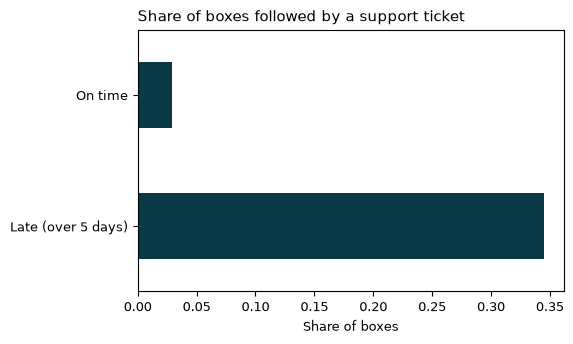

In [8]:
ticket_rate = boxes.groupby('late')['ticket'].mean()
ticket_rate.index = ['On time', 'Late (over 5 days)']

ax = ticket_rate.plot.barh(color='#0b3a47')
ax.invert_yaxis()
ax.set_title('Share of boxes followed by a support ticket')
ax.set_xlabel('Share of boxes')
ax.set_ylabel('')
plt.show()

### Testing the gap

In [9]:
late_ticket = pd.crosstab(boxes['late'], boxes['ticket'])
late_test = stats.chi2_contingency(late_ticket)

counts = boxes.groupby('late')['ticket'].agg(['sum', 'count'])
low, high = confint_proportions_2indep(
    counts.loc[True, 'sum'], counts.loc[True, 'count'],
    counts.loc[False, 'sum'], counts.loc[False, 'count'])
gap = ticket_rate.iloc[1] - ticket_rate.iloc[0]
print(p_text(late_test.pvalue))
print(f"Cramér's V: {stats.contingency.association(late_ticket):.2f}")
print(f'Late minus on time: {gap * 100:.1f} points, '
      f'95% CI {low * 100:.1f} to {high * 100:.1f} points')

p < 0.001
Cramér's V: 0.39
Late minus on time: 31.6 points, 95% CI 29.6 to 33.6 points


In [10]:
print(f"Late share of boxes: {boxes['late'].mean():.1%}")
print(f"Late share of tickets: {linked['late'].mean():.1%}")

Late share of boxes: 8.8%
Late share of tickets: 53.4%


## 18.4 Question 2: Do Ticket-Openers Cancel More?

In [11]:
customers['cancelled'] = customers['customer_id'].isin(
    cancellations['customer_id'])
customers['has_ticket'] = customers['customer_id'].isin(
    tickets['customer_id'])
customers.groupby('has_ticket')['cancelled'].agg(
    ['mean', 'count']).round(3)

,mean,count
has_ticket,,
False,0.585,3106
True,0.500,1104


In [12]:
box_count = boxes.groupby('customer_id').size()
customers['boxes'] = customers['customer_id'].map(box_count)
customers.groupby('has_ticket')['boxes'].median()

has_ticket
False    3.0
True     9.0
Name: boxes, dtype: float64

### Comparing like with like

In [13]:
last_box = boxes.groupby('customer_id')['order_date'].transform('max')
boxes['cancel_after'] = ((boxes['order_date'] == last_box)
                         & boxes['customer_id'].isin(
                             cancellations['customer_id']))

final = boxes[boxes['cancel_after']].merge(
    cancellations, on='customer_id', validate='one_to_one')
wait = (final['cancel_date'] - final['order_date']).dt.days
print(f'{len(final):,} cancellations, '
      f'{wait.min()} to {wait.max()} days after the last box')

2,369 cancellations, 5 to 27 days after the last box

In [14]:
data_end = pd.Timestamp('2025-12-31')
cutoff = data_end - pd.DateOffset(months=1)
settled = boxes[boxes['order_date'] <= cutoff].copy()
print(f'Boxes shipped by {cutoff:%B %d, %Y}: {len(settled):,}')
settled.groupby('ticket')['cancel_after'].agg(
    ['mean', 'count']).round(3)

Boxes shipped by November 30, 2025: 22,326


,mean,count
ticket,,
False,0.098,21058
True,0.177,1268


In [15]:
cancel_grid = pd.pivot_table(settled, index='late', columns='ticket',
                             values='cancel_after', aggfunc='mean')
cancel_grid.index = ['On time', 'Late']
cancel_grid.columns = ['No ticket', 'Ticket']
cancel_grid.round(3)

,No ticket,Ticket
On time,0.091,0.109
Late,0.205,0.241


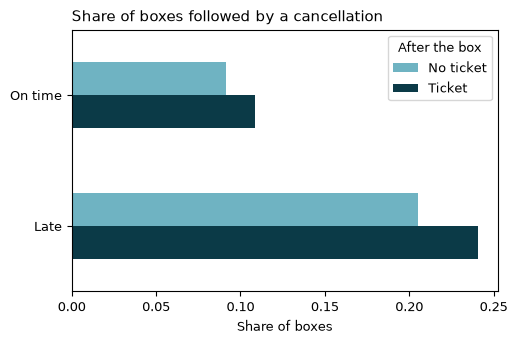

In [16]:
ax = cancel_grid.plot.barh(color=['#6fb3c2', '#0b3a47'])
ax.invert_yaxis()
ax.set_title('Share of boxes followed by a cancellation')
ax.set_xlabel('Share of boxes')
ax.set_ylabel('')
ax.legend(title='After the box')
plt.show()

### Holding lateness steady

In [17]:
for column in ['late', 'ticket', 'cancel_after']:
    settled[column] = settled[column].astype(int)

ticket_model = smf.logit('cancel_after ~ late + ticket',
                         data=settled).fit(disp=0)
ticket_odds = np.exp(ticket_model.conf_int())
ticket_odds.columns = ['low', 'high']
ticket_odds['odds_ratio'] = np.exp(ticket_model.params)
ticket_odds['p'] = ticket_model.pvalues.map(p_text)
ticket_odds.round(2)

,low,high,odds_ratio,p
Intercept,0.10,0.11,0.10,p < 0.001
late,2.25,2.94,2.57,p < 0.001
ticket,1.03,1.45,1.22,p = 0.021


In [18]:
last_tickets = linked.merge(final[['order_id', 'cancel_date']],
                            on='order_id', validate='one_to_one')
opened_after = last_tickets['opened_date'] > last_tickets['cancel_date']
print(f"{opened_after.sum()} of {len(last_tickets)} tickets on a "
      "canceller's last box came after the cancel date")

19 of 239 tickets on a canceller's last box came after the cancel date


## 18.5 Question 3: Are Late-Delivery Tickets Slower to Resolve?

In [19]:
topic_hours = tickets.groupby('topic')['hours_to_resolve'].agg(
    ['count', 'mean', 'median'])
topic_hours.sort_values('mean', ascending=False).round(1)

,count,mean,median
topic,,,
Late delivery,612,9.8,6.1
Other,151,9.4,5.3
Change address,153,9.0,5.7
Product quality,214,9.0,6.5
Billing,250,8.9,6.0


In [20]:
hours_by_topic = [group['hours_to_resolve']
                  for _, group in tickets.groupby('topic')]
topic_test = stats.kruskal(*hours_by_topic)
print(p_text(topic_test.pvalue))

p = 0.793


In [21]:
ranks = tickets['hours_to_resolve'].rank()
ranks.groupby(tickets['topic']).mean().round(0)

topic
Billing            688.0
Change address     679.0
Late delivery      695.0
Other              660.0
Product quality    711.0
Name: hours_to_resolve, dtype: float64

## 18.6 Question 4: What Goes With Satisfaction?

In [22]:
survey_day = survey['response_date'].min()
before = boxes[boxes['order_date'] < survey_day]
late_share = before.groupby('customer_id')['late'].mean()

responses = survey.merge(customers, on='customer_id',
                         validate='one_to_one')
responses['had_late_box'] = (
    responses['customer_id'].map(late_share) > 0)
responses['happy'] = responses['satisfaction'] >= 4
print(f"{len(responses)} replies, "
      f"{responses['had_late_box'].sum()} with a late box")

532 replies, 233 with a late box


In [23]:
for column in ['plan', 'region', 'had_late_box']:
    print(responses.groupby(column).agg(
        satisfaction=('satisfaction', 'mean'),
        happy=('happy', 'mean'),
        count=('satisfaction', 'size')).round(2), '\n')

          satisfaction  happy  count
plan                                
Basic             3.69   0.61    133
Premium           3.70   0.59    164
Standard          3.56   0.54    235 

           satisfaction  happy  count
region                               
Midwest            3.63   0.58    109
Northeast          3.57   0.51    136
South              3.75   0.63    149
West               3.57   0.56    138 

              satisfaction  happy  count
had_late_box                            
False                 3.75   0.63    299
True                  3.48   0.50    233 



### Three tests, adjusted together

In [24]:
def split(column):
    return [group['satisfaction']
            for _, group in responses.groupby(column)]


late_yes = responses.loc[responses['had_late_box'], 'satisfaction']
late_no = responses.loc[~responses['had_late_box'], 'satisfaction']
late_mw = stats.mannwhitneyu(late_yes, late_no)

raw_p = [stats.kruskal(*split('plan')).pvalue,
         stats.kruskal(*split('region')).pvalue,
         late_mw.pvalue]
_, holm_p, _, _ = multipletests(raw_p, method='holm')
for name, p_raw, p_adj in zip(['plan', 'region', 'late box'],
                              raw_p, holm_p):
    print(f'{name:>9}: raw {p_text(p_raw)}, Holm {p_text(p_adj)}')

     plan: raw p = 0.257, Holm p = 0.410
   region: raw p = 0.205, Holm p = 0.410
 late box: raw p < 0.001, Holm p < 0.001


In [25]:
late_wins = late_mw.statistic / (len(late_yes) * len(late_no))
gap = late_yes.mean() - late_no.mean()
print(f'A late-box customer scores higher {late_wins:.0%} of the time')
print(f'Average: {late_yes.mean():.2f} vs {late_no.mean():.2f} '
      f'({gap:+.2f} points)')

A late-box customer scores higher 41% of the time
Average: 3.48 vs 3.75 (-0.26 points)


In [26]:
responses['boxes_before'] = responses['customer_id'].map(
    before.groupby('customer_id').size())
print(responses.groupby('had_late_box')['boxes_before'].median())
box_model = smf.ols('satisfaction ~ had_late_box + boxes_before',
                    data=responses).fit()
held_gap = box_model.params['had_late_box[T.True]']
print(f'Late-box gap, box count held steady: {held_gap:+.2f} points')

had_late_box
False     8.0
True     13.0
Name: boxes_before, dtype: float64
Late-box gap, box count held steady: -0.26 points


## 18.7 Question 5: Is the New Blend Preferred in Every Plan?

In [27]:
plan_order = ['Basic', 'Standard', 'Premium']
rows = []
for plan in plan_order:
    group = responses[responses['plan'] == plan]
    gain = group['new_blend_rating'] - group['house_blend_rating']
    test = stats.ttest_rel(group['new_blend_rating'],
                           group['house_blend_rating'])
    ci = test.confidence_interval()
    rows.append({'plan': plan, 'n': len(group),
                 'gain': gain.mean(), 'low': ci.low, 'high': ci.high,
                 'prefer_new': (gain > 0).sum(),
                 'prefer_house': (gain < 0).sum(),
                 'p_raw': test.pvalue})
blend = pd.DataFrame(rows).set_index('plan')

_, holm_p, _, _ = multipletests(blend['p_raw'], method='holm')
blend['p_holm'] = [p_text(p) for p in holm_p]
blend[['n', 'gain', 'low', 'high', 'prefer_new', 'prefer_house',
       'p_holm']].round(2)

,n,gain,low,high,prefer_new,prefer_house,p_holm
plan,,,,,,,
Basic,133,0.47,0.24,0.71,61,26,p < 0.001
Standard,235,0.40,0.22,0.58,109,60,p < 0.001
Premium,164,0.43,0.25,0.62,76,35,p < 0.001


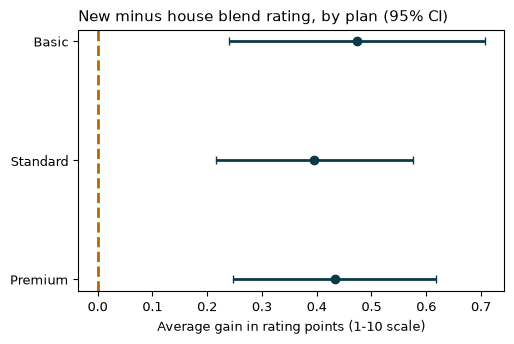

In [28]:
fig, ax = plt.subplots()
ax.errorbar(blend['gain'], blend.index,
            xerr=[blend['gain'] - blend['low'],
                  blend['high'] - blend['gain']],
            fmt='o', color='#0b3a47', capsize=3)
ax.axvline(0, color='#b26a00', linestyle='--')
ax.invert_yaxis()
ax.set_title('New minus house blend rating, by plan (95% CI)')
ax.set_xlabel('Average gain in rating points (1-10 scale)')
plt.show()

In [29]:
gain_all = (responses['new_blend_rating']
            - responses['house_blend_rating'])
gains = [gain_all[responses['plan'] == plan] for plan in plan_order]
print(p_text(stats.kruskal(*gains).pvalue))

p = 0.943
